In [20]:
from dizx.zx_diagram import SPIDERS, PAULI, PAULI_BITS


## Example

Build a CNOT gate ZX diagram

In [21]:
from dizx.zx_diagram import ZXDiagram
import networkx as nx

graph = nx.MultiGraph()

nodes = [0,1,2,3,4,5]
types = {0: "P", 1: "Z", 2: "P", 3: "P", 4: "X", 5: "P"}


time_edges = [(0,1), (1,2), (3,4), (4,5)]
gate_edges = [(1,4)]

graph.add_nodes_from(nodes)

for edge in time_edges + gate_edges:
    graph.add_edge(*edge)

inputs = [0, 3]
outputs = [2, 5]

zx = ZXDiagram(graph, types, inputs=inputs, outputs=outputs)

In [22]:
zx.validate()

for node in zx.graph.nodes:
    print(f"Node {node}: legs={zx.legs(node)}")

Node 0: legs=[0]
Node 1: legs=[0, 1, 2]
Node 2: legs=[1]
Node 3: legs=[3]
Node 4: legs=[2, 3, 4]
Node 5: legs=[4]


In [23]:
from dizx.zx_diagram import PauliWeb
import numpy as np
print(zx.graph.edges)


XI_XX = np.array([1,1,0,1,1,0,0,0,0,0])

web = PauliWeb(zx, vec=XI_XX)

print(web.pauli((0,1,0)))

[(0, 1, 0), (1, 2, 0), (1, 4, 0), (3, 4, 0), (4, 5, 0)]
X


<Axes3D: >

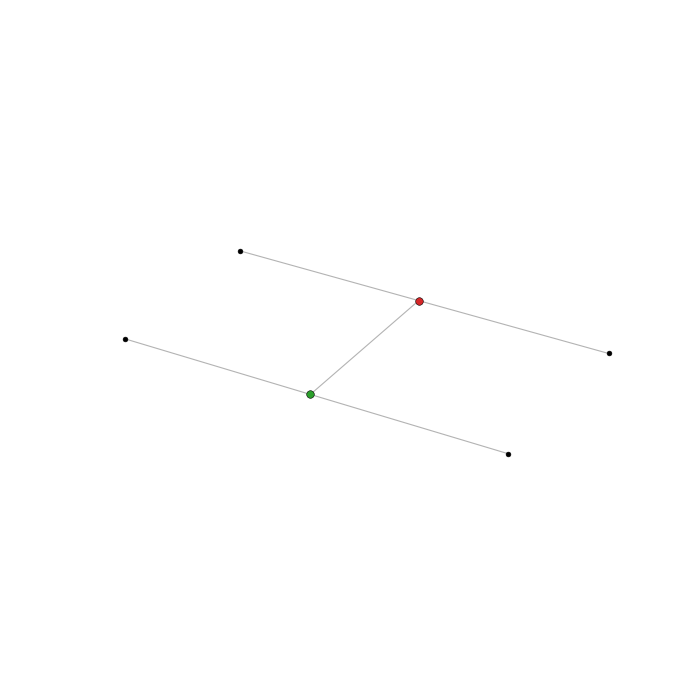

In [24]:
%matplotlib widget

from dizx.zx_diagram import draw_diagram

positions = {}
for node in zx.graph.nodes:
    positions[node] = (node%3, node//3, 0)

draw_diagram(zx, positions=positions)


[[1 1 0 0 0 0 0 0 0 0]
 [1 0 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0 1 1 0]
 [0 0 0 0 0 0 0 1 0 1]
 [0 0 1 1 1 0 0 0 0 0]]
Constraint matrix A in reduced row echelon form:
[[1 0 0 1 1 0 0 0 0 0]
 [0 1 0 1 1 0 0 0 0 0]
 [0 0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 1 1 0 0 1]
 [0 0 0 0 0 0 0 1 0 1]
 [0 0 0 0 0 0 0 0 1 1]]
Pivot columns in reduced row echelon form:
[0, 1, 2, 5, 7, 8]


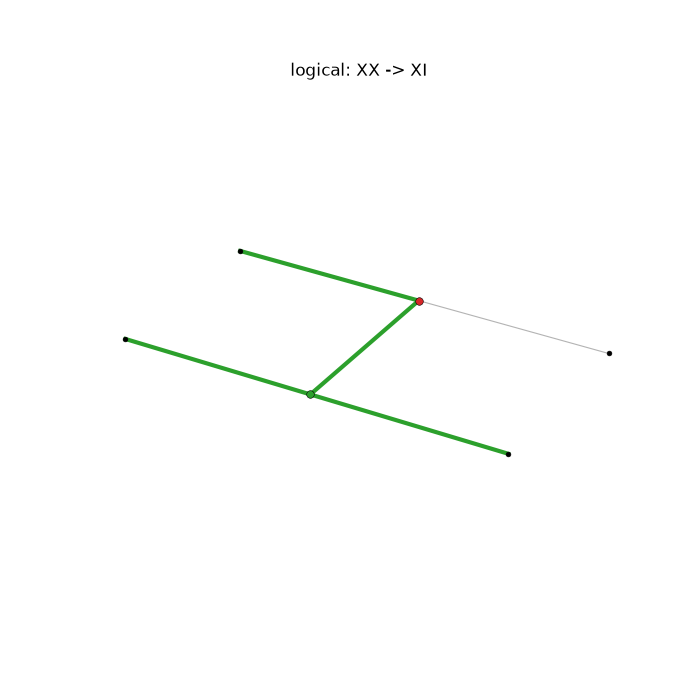

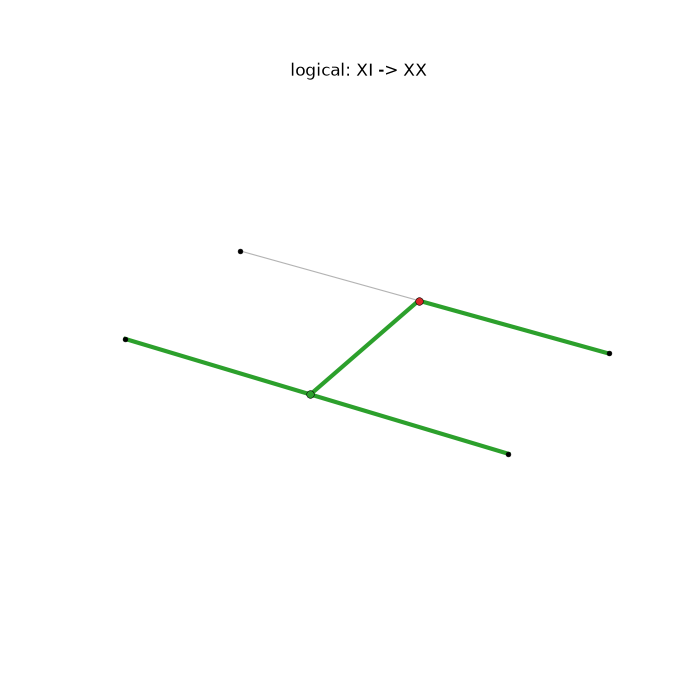

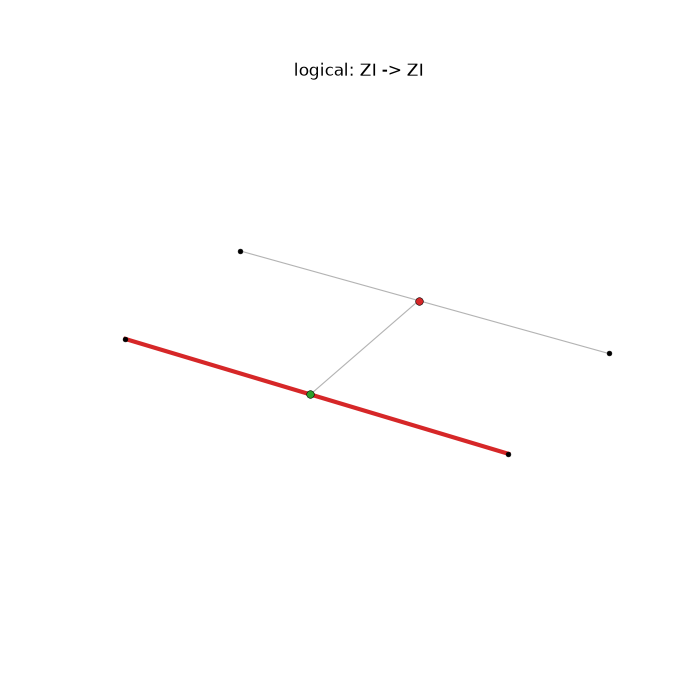

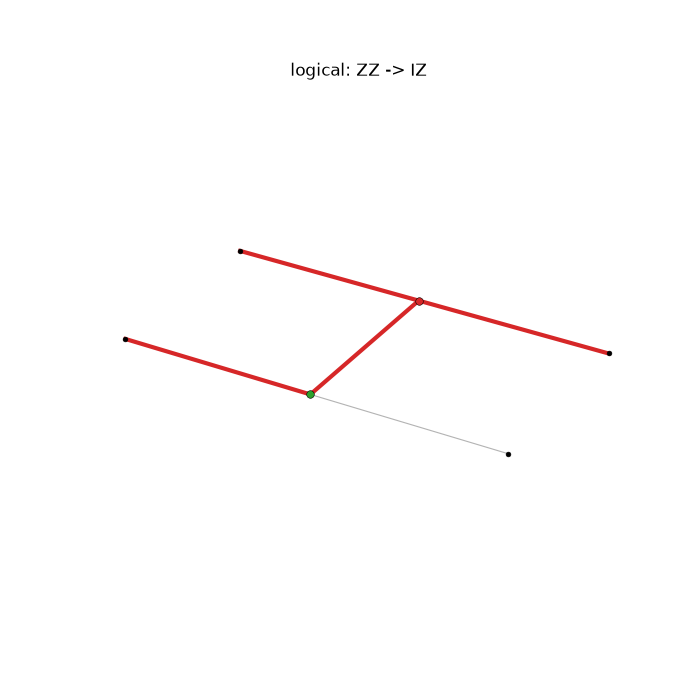

In [25]:
from dizx._f2 import rref

A, _ = zx.web_constraints()

print(A.toarray())

A_r = rref(A.toarray())

print(f"Constraint matrix A in reduced row echelon form:\n{A_r[0]}")
print(f"Pivot columns in reduced row echelon form:\n{A_r[1]}")

for w in zx.web_space():
    draw_diagram(zx, positions, w)




## Composition: CNOT(0 → 1) ; CNOT(1 → 2)

Second diagram $d_2$: a CNOT with control on qubit 1 and target on a new qubit 2. It has two inputs and two outputs. We join output `5` of $d_1$ (qubit 1) to input `10` of $d_2$ (qubit 1). Input `13` (qubit 2) stays open, so the composite has three inputs and three outputs.

A web of the composite is a web $w_1$ of $d_1$ and a web $w_2$ of $d_2$ that **agree on the joined edge**. Given bases $V_1$ ($n_1$ webs) and $V_2$ ($n_2$ webs), we look for combinations $a = (a_1, a_2) \in \mathbb{F}_2^{n_1 + n_2}$ with

$$
a_1 O_1 = a_2 I_2 \quad\Longleftrightarrow\quad (a_1, a_2) \begin{pmatrix} O_1 \\ I_2 \end{pmatrix} = 0,
$$

where $O_1$ holds the $(x \mid z)$ bits of $d_1$'s webs on the joined output and $I_2$ those of $d_2$'s webs on the joined input.

((10, 11, 0), (11, 12, 0), (11, 14, 0), (13, 14, 0), (14, 15, 0))


<Axes3D: >

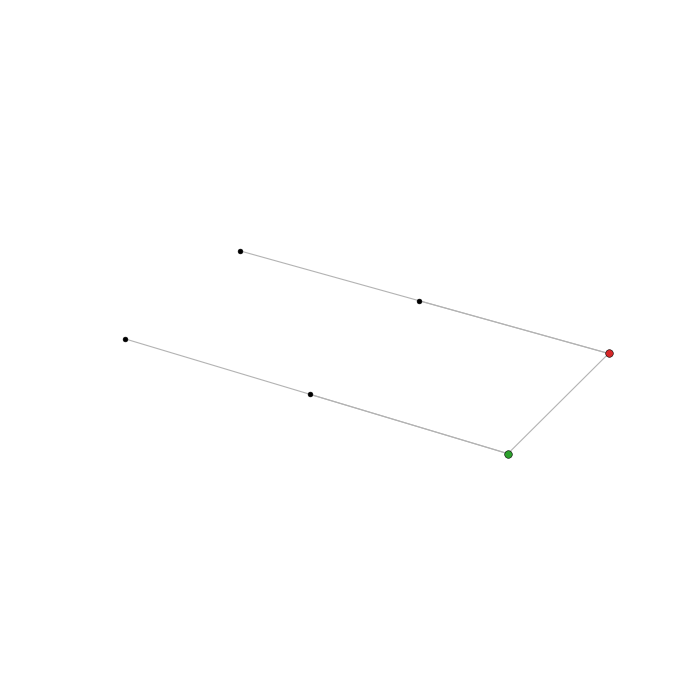

In [26]:
graph2 = nx.MultiGraph()

types2 = {10: "P", 11: "Z", 12: "P", 13: "P", 14: "X", 15: "P"}

time_edges2 = [(10, 11), (11, 12), (13, 14), (14, 15)]
gate_edges2 = [(11, 14)]

graph2.add_nodes_from(types2)
for edge in time_edges2 + gate_edges2:
    graph2.add_edge(*edge)

zx2 = ZXDiagram(graph2, types2, inputs=[10, 13], outputs=[12, 15])
print(zx2.edges)

# Qubit 1 on row 1, qubit 2 on row 2.
positions2 = {v: (v % 3, 1 + (v - 10) // 3, 0) for v in zx2.graph.nodes}
draw_diagram(zx2, positions=positions2)

### Bases $V_1$ and $V_2$

Each CNOT has a 4-dimensional web space ($2n - \operatorname{rank} A = 10 - 6$). Take the `web_space` bases and stack them as the rows of web matrices.

In [27]:
from dizx.zx_diagram import web_matrix, port_bits

webs1 = zx.web_space()
webs2 = zx2.web_space()
V1 = web_matrix(webs1, zx.n_edges).toarray()
V2 = web_matrix(webs2, zx2.n_edges).toarray()

for name, ws in (("d1", webs1), ("d2", webs2)):
    for k, w in enumerate(ws):
        p_in, p_out = w.boundary()
        print(f"{name} web {k}: {p_in} -> {p_out}")

d1 web 0: XX -> XI
d1 web 1: XI -> XX
d1 web 2: ZI -> ZI
d1 web 3: ZZ -> IZ
d2 web 0: XX -> XI
d2 web 1: XI -> XX
d2 web 2: ZI -> ZI
d2 web 3: ZZ -> IZ


### Seam bits $O_1$ and $I_2$

Row $k$ of $O_1$ is $(x \mid z)$ of $d_1$'s web $k$ on the edge of output `5`; row $k$ of $I_2$ is the same for $d_2$'s web $k$ on the edge of input `10`.

In [28]:
join = [(5, 10)]
O1 = port_bits(zx, V1, [5])
I2 = port_bits(zx2, V2, [10])
print(f"O1 =\n{O1}")
print(f"I2 =\n{I2}")

O1 =
[[0 0]
 [1 0]
 [0 0]
 [0 1]]
I2 =
[[1 0]
 [1 0]
 [0 1]
 [0 1]]


### Solving the glue condition

Stack $M = \begin{pmatrix} O_1 \\ I_2 \end{pmatrix}$. The composite's webs are the left nullspace $\{a : aM = 0\}$, i.e. `nullspace(M.T)`, of dimension

$$
\dim = (n_1 + n_2) - \operatorname{rank} M .
$$

Here the seam is one qubit, so $M$ has 2 columns ($x$, $z$), and both $X$ and $Z$ cross it, so $\operatorname{rank} M = 2$ and $\dim = 8 - 2 = 6$: two per qubit, as for any 3-qubit unitary.

In [29]:
from dizx._f2 import nullspace, rank

M = np.vstack([O1, I2])
n1, n2 = len(webs1), len(webs2)
print(f"M =\n{M}")
print(f"rank M = {rank(M)}, dim = {n1 + n2} - {rank(M)} = {n1 + n2 - rank(M)}")

combos = nullspace(M.T)
print(f"combinations a = (a1 | a2):\n{combos}")
for a in combos:
    a1, a2 = a[:n1], a[n1:]
    print(f"d1 webs {np.flatnonzero(a1)}, d2 webs {np.flatnonzero(a2)}: "
          f"a1 O1 = {a1 @ O1 % 2}, a2 I2 = {a2 @ I2 % 2}")

M =
[[0 0]
 [1 0]
 [0 0]
 [0 1]
 [1 0]
 [1 0]
 [0 1]
 [0 1]]
rank M = 2, dim = 8 - 2 = 6
combinations a = (a1 | a2):
[[1 0 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0]
 [0 1 0 0 1 0 0 0]
 [0 1 0 0 0 1 0 0]
 [0 0 0 1 0 0 1 0]
 [0 0 0 1 0 0 0 1]]
d1 webs [0], d2 webs []: a1 O1 = [0 0], a2 I2 = [0 0]
d1 webs [2], d2 webs []: a1 O1 = [0 0], a2 I2 = [0 0]
d1 webs [1], d2 webs [0]: a1 O1 = [1 0], a2 I2 = [1 0]
d1 webs [1], d2 webs [1]: a1 O1 = [1 0], a2 I2 = [1 0]
d1 webs [3], d2 webs [2]: a1 O1 = [0 1], a2 I2 = [0 1]
d1 webs [3], d2 webs [3]: a1 O1 = [0 1], a2 I2 = [0 1]


### The composite diagram

Remove ports `5` and `10` and join their neighbours, X spider `4` and Z spider `11`, by a new edge. (They are different colours, so there is no spider fusion.)

<Axes3D: >

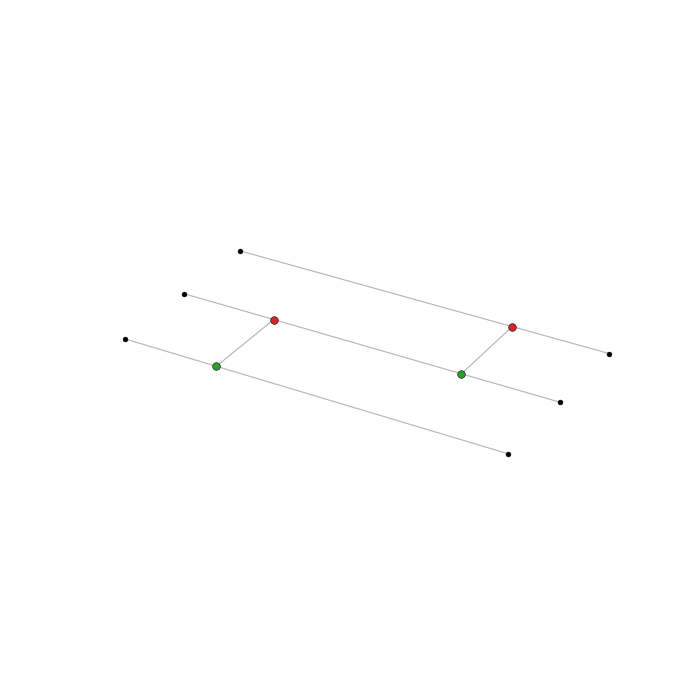

In [30]:
graph12 = nx.MultiGraph()

types12 = {v: t for v, t in types.items() if v != 5}
types12.update({v: t for v, t in types2.items() if v != 10})

seam_edge = (4, 11)
edges1 = [e for e in time_edges + gate_edges if 5 not in e]
edges2 = [e for e in time_edges2 + gate_edges2 if 10 not in e]

graph12.add_nodes_from(types12)
for edge in edges1 + [seam_edge] + edges2:
    graph12.add_edge(*edge)

zx12 = ZXDiagram(graph12, types12, inputs=[0, 3, 13], outputs=[2, 12, 15])

positions12 = {0: (0, 0, 0), 1: (1, 0, 0), 2: (4, 0, 0),
               3: (0, 1, 0), 4: (1, 1, 0), 11: (3, 1, 0), 12: (4, 1, 0),
               13: (0, 2, 0), 14: (3, 2, 0), 15: (4, 2, 0)}
draw_diagram(zx12, positions=positions12)

### Gluing the webs

For each combination $a = (a_1, a_2)$:

1. $w_1 = a_1 V_1$ and $w_2 = a_2 V_2$ (mod 2) are webs of $d_1$ and $d_2$;
2. on every edge except the seam, the composite web is $w_1$ (on $d_1$'s edges) or $w_2$ (on $d_2$'s edges);
3. the seam edge `(4, 11)` replaces both `(4, 5)` and `(10, 11)`, and since $a_1 O_1 = a_2 I_2$ the two webs put the same Pauli on it.

In [31]:
seam = {frozenset((4, 5)): (4, 11, 0), frozenset((10, 11)): (4, 11, 0)}

def onto_composite(w):
    # A web's {edge: pauli} with the seam edge renamed to the composite's.
    return {seam.get(frozenset(e[:2]), e): p for e, p in w.support().items()}

def glue(a):
    a1, a2 = a[:n1], a[n1:]
    w1 = PauliWeb(zx, a1 @ V1 % 2)
    w2 = PauliWeb(zx2, a2 @ V2 % 2)
    p1, p2 = onto_composite(w1), onto_composite(w2)
    assert p1.get((4, 11, 0), "I") == p2.get((4, 11, 0), "I"), "webs disagree on the seam"
    return PauliWeb.from_paulis(zx12, {**p1, **p2})

glued = [glue(a) for a in combos]
for w in glued:
    p_in, p_out = w.boundary()
    print(f"{p_in} -> {p_out}   valid: {w.is_valid()}")

print(f"rank of glued webs = {rank(web_matrix(glued, zx12.n_edges).toarray())}, "
      f"dim W(D) of the composite = {len(zx12.web_space())}")

XXI -> XII   valid: True
ZII -> ZII   valid: True
XIX -> XXI   valid: True
XII -> XXX   valid: True
ZZI -> IZI   valid: True
ZZZ -> IIZ   valid: True
rank of glued webs = 6, dim W(D) of the composite = 6


Each glued web is the Heisenberg action of $\mathrm{CNOT}_{12} \cdot \mathrm{CNOT}_{01}$, e.g. $X_0 \mapsto X_0 X_1 \mapsto X_0 X_1 X_2$ (the web `XII -> XXX`) and $Z_0 Z_1 Z_2 \mapsto Z_1 Z_2 \mapsto Z_2$ (the web `ZZZ -> IIZ`). The rank check confirms that the six glued webs are independent and span the composite's whole web space.

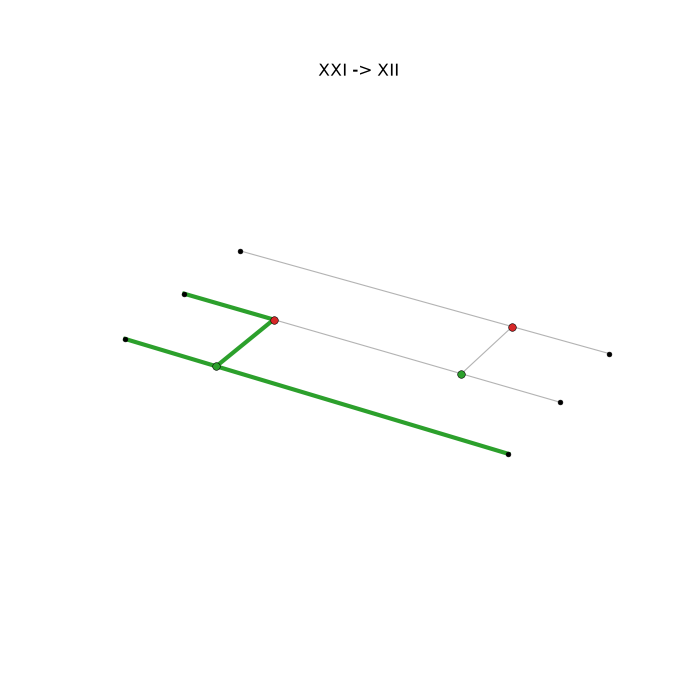

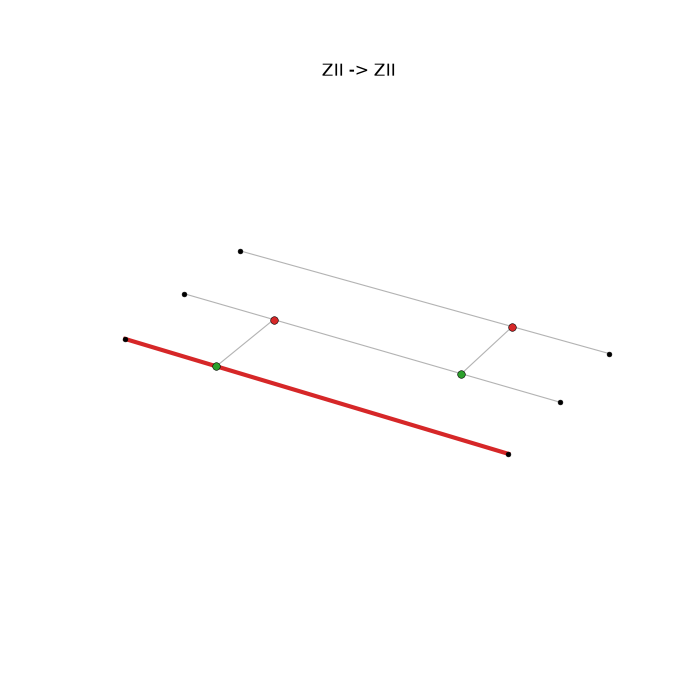

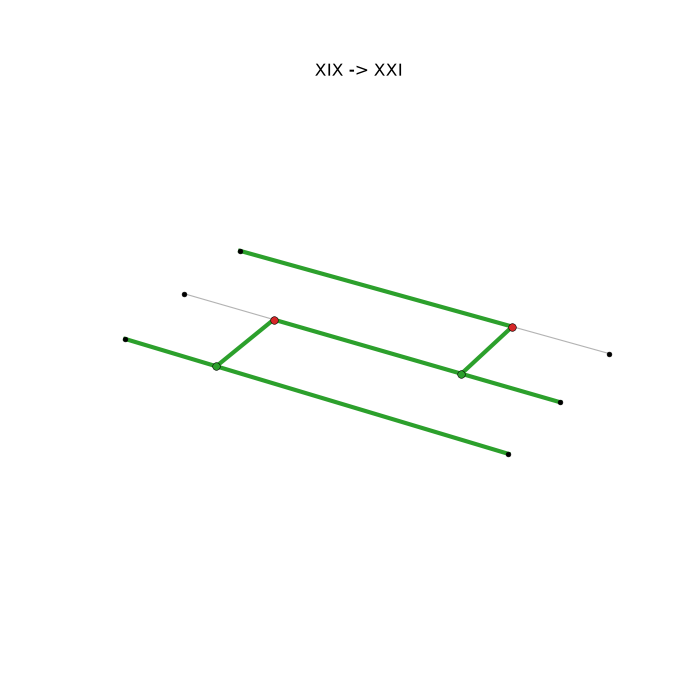

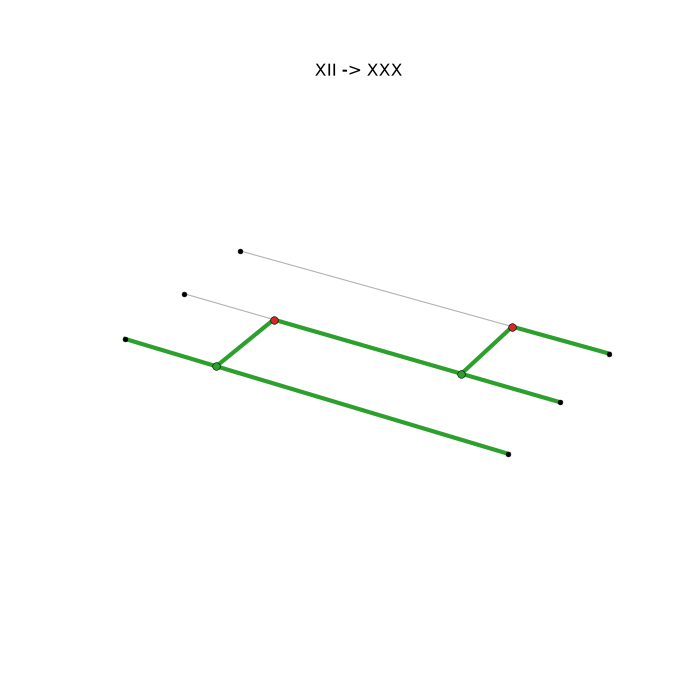

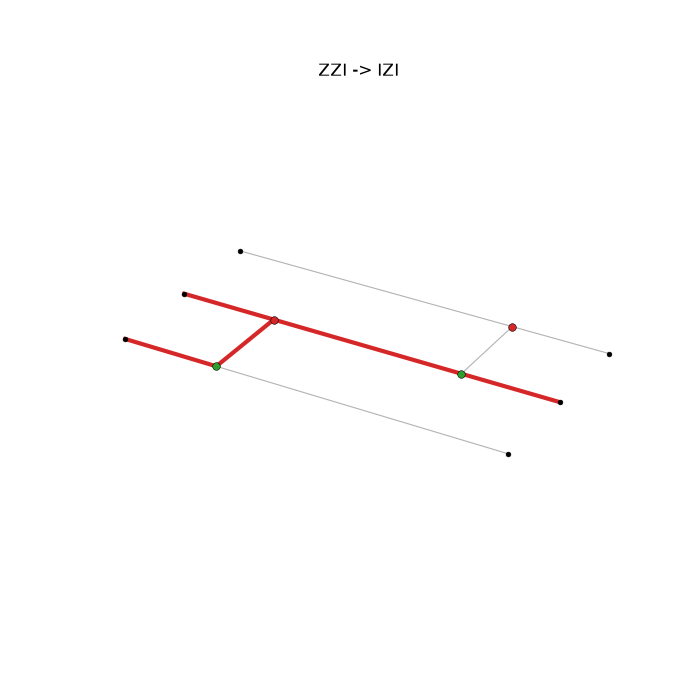

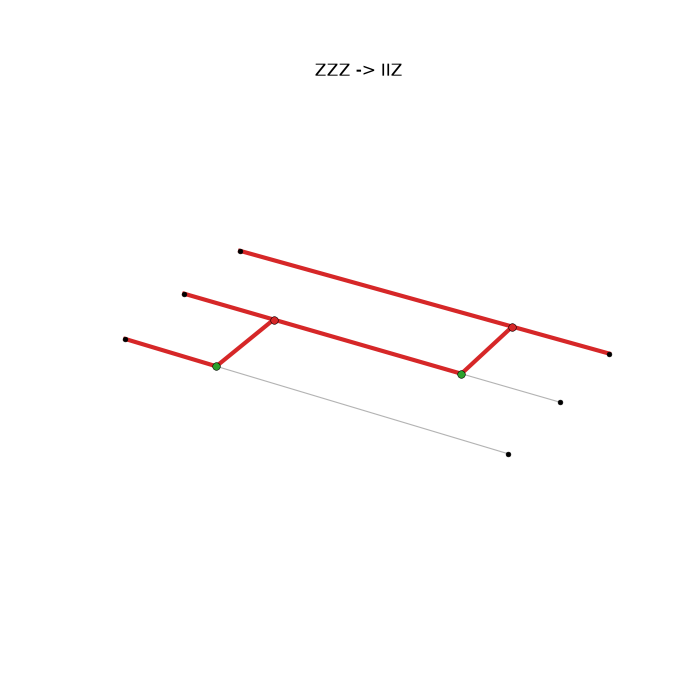

In [32]:
for w in glued:
    p_in, p_out = w.boundary()
    draw_diagram(zx12, positions12, w, title=f"{p_in} -> {p_out}")

### Check against `dizx.compose`

`compose` does the same computation for `SEDiagram`s. It assumes ports are named `("in", q)` / `("out", q)`, so relabel the ports first; it then joins `("out", 1)` to `("in", 1)` by default. Its basis can differ from ours (it prefers webs carried straight through), but the span must be the same: stacking both sets still has rank 6.

In [33]:
from dizx.zx_diagram import SEDiagram, compose, relabel

ports1 = {0: ("in", 0), 3: ("in", 1), 2: ("out", 0), 5: ("out", 1)}
ports2 = {10: ("in", 1), 13: ("in", 2), 12: ("out", 1), 15: ("out", 2)}
sed1 = relabel(SEDiagram(zx.graph, zx.types, zx.inputs, zx.outputs, logicals=webs1),
               lambda v: ports1.get(v, v))
sed2 = relabel(SEDiagram(zx2.graph, zx2.types, zx2.inputs, zx2.outputs, logicals=webs2),
               lambda v: ports2.get(v, v))
sed12, fused = compose(sed1, sed2)

for w in sed12.logicals:
    p_in, p_out = w.boundary()
    print(f"compose: {p_in} -> {p_out}")

ports12 = {**ports1, **ports2}
ours = [PauliWeb.from_paulis(sed12, {(ports12.get(u, u), ports12.get(v, v), k): p
                                     for (u, v, k), p in w.support().items()})
        for w in glued]
print(f"rank of ours + compose's = {rank(web_matrix(ours + sed12.logicals, sed12.n_edges).toarray())}")

compose: XXI -> XII
compose: ZII -> ZII
compose: XIX -> XXI
compose: ZZI -> IZI
compose: IXI -> IXX
compose: ZZZ -> IIZ
rank of ours + compose's = 6
